In [1]:
# load data
import pandas as pd

df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [2]:
# EDA
print(f'Cek 5 data teratas \n {df.head()} \n')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f'Cek missing values \n {df.isnull().sum()}')

Cek 5 data teratas 
    gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0   

Cek tipe data 
 gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int6

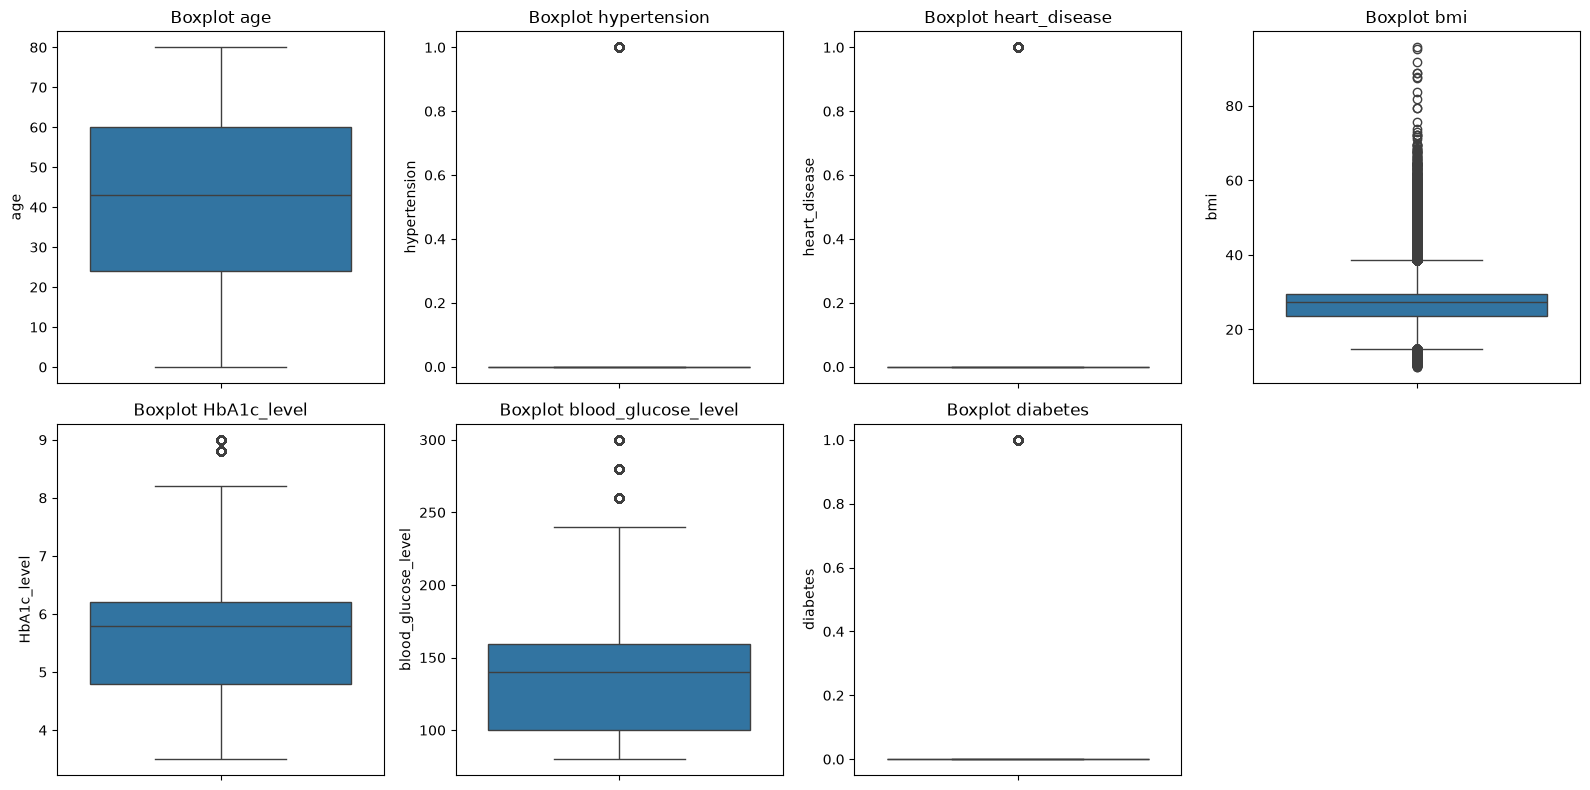

In [3]:
# outlier
import math
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = df.select_dtypes(include='number').columns

## Outlier
n_cols = 4  # jumlah plot per baris, silakan diubah
n_rows = math.ceil(len(numerical_columns) / n_cols)

plt.figure(figsize=(4 * n_cols, 4 * n_rows))

for i, column in enumerate(numerical_columns):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(y=df[column])
    plt.title(f'Boxplot {column}')

plt.tight_layout()
plt.show()

In [4]:
# handle outlier
numerical_columns = df.select_dtypes(include='number').columns

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
)

outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_mask.sum(),
    'Percentage': outlier_mask.mean() * 100
})

outlier_summary.sort_values(
    by='Outlier Count',
    ascending=False
)

,Outlier Count,Percentage
diabetes,8500,8.500
hypertension,7485,7.485
bmi,7086,7.086
heart_disease,3942,3.942
blood_glucose_level,2038,2.038
HbA1c_level,1315,1.315
age,0,0.000


In [12]:
# feature selection
x = df.drop(columns = ['diabetes'])
y = df['diabetes']

In [14]:
# split data
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

In [20]:
# training model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Menyiapkan Dataset (Contoh: Fitur Umur & Gaji untuk memprediksi Beli=1 / Tidak=0)
np.random.seed(42)
X = np.random.randint(18, 60, size=(200, 2)) # 2 fitur acak
y = (X[:, 0] * 0.05 + X[:, 1] * 0.02 + np.random.normal(0, 1, 200) > 3.5).astype(int) # Label binary 0 atau 1

# 2. Memisah data menjadi Training set dan Test set (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Scaling Fitur (Sangat direkomendasikan untuk Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Inisialisasi dan Melatih Model Logistic Regression
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

# 5. Melakukan Prediksi pada Data Uji (Test set)
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled) # Mengambil probabilitasnya

# 6. Evaluasi Performa Model
print("--- Evaluasi Model ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.2f}\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 7. Contoh Prediksi Data Baru
data_baru = np.array([[35, 50]]) # Umur 35, Skor/Gaji 50
data_baru_scaled = scaler.transform(data_baru)

prediksi = model.predict(data_baru_scaled)
probabilitas = model.predict_proba(data_baru_scaled)

print("--- Hasil Prediksi Data Baru ---")
print(f"Hasil Klasifikasi : {prediksi[0]}")
print(f"Probabilitas Class 0: {probabilitas[0][0]:.2%}")
print(f"Probabilitas Class 1: {probabilitas[0][1]:.2%}")

--- Evaluasi Model ---
Accuracy Score: 0.68

Confusion Matrix:
[[24  5]
 [ 8  3]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.83      0.79        29
           1       0.38      0.27      0.32        11

    accuracy                           0.68        40
   macro avg       0.56      0.55      0.55        40
weighted avg       0.65      0.68      0.66        40

--- Hasil Prediksi Data Baru ---
Hasil Klasifikasi : 0
Probabilitas Class 0: 72.68%
Probabilitas Class 1: 27.32%


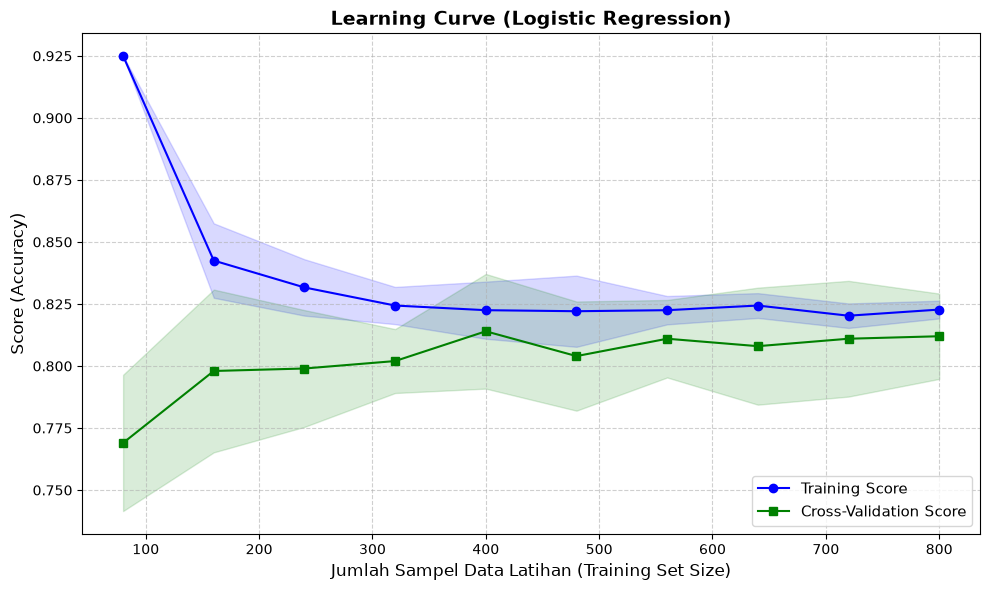

In [21]:
# learning curve
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import learning_curve
from sklearn.preprocessing import StandardScaler

# 1. Menyiapkan Dataset Sintetis
X, y = make_classification(
    n_samples=1000, 
    n_features=20, 
    n_informative=15, 
    n_redundant=5, 
    random_state=42
)

# Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Inisialisasi Model
model = LogisticRegression()

# 3. Menghitung Learning Curve ( Cross-Validation )
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,
    X=X_scaled,
    y=y,
    train_sizes=np.linspace(0.1, 1.0, 10), # 10 titik porsi training (10% - 100%)
    cv=5,                                  # 5-Fold Cross Validation
    scoring='accuracy',                    # Metrik evaluasi
    n_jobs=-1                              # Menggunakan semua core CPU
)

# 4. Menghitung Rata-rata dan Standar Deviasi Skor
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# 5. Visualisasi Learning Curve
plt.figure(figsize=(10, 6))

# Plot Training Score
plt.plot(train_sizes, train_mean, color='blue', marker='o', label='Training Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')

# Plot Validation / Test Score
plt.plot(train_sizes, test_mean, color='green', marker='s', label='Cross-Validation Score')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='green')

# Fitur Tambahan Plot
plt.title('Learning Curve (Logistic Regression)', fontsize=14, fontweight='bold')
plt.xlabel('Jumlah Sampel Data Latihan (Training Set Size)', fontsize=12)
plt.ylabel('Score (Accuracy)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()